# 06_AngleCheck — Kiểm tra model v2 sai từ góc xoay nào (Task 6a)

Notebook này **không train gì và không sửa 04_Trainv2**. Nó chỉ nạp checkpoint đã có, xoay tập test theo từng góc rồi đo xem độ chính xác giảm từ góc nào, ở trục nào.

**Cách chạy:** kích hoạt môi trường `C:\envs\train-gpu\Scripts\activate.bat`, mở notebook bằng kernel `train-gpu`, chạy lần lượt cell 1 → 8.

**Cần có sẵn:** `Data_321/manifest.csv`, các file landmark, `Data_321/checkpoints_v2/all/TCN.pt` và `GRU.pt`. Nếu có `Data_321/checkpoints/` (bản v1) thì notebook tự nạp thêm để so sánh.

In [1]:
#cell 1: đọc manifest và dựng tensor TEST giống 04_Trainv2 (bắt buộc CUDA)
import numpy as np, pandas as pd, torch, math
from pathlib import Path

assert torch.cuda.is_available(), "Chưa bật CUDA; notebook này không chạy trên CPU."
dev = "cuda"
BASE = Path.home() / "Downloads" / "Data_321"
assert (BASE / "manifest.csv").exists(), f"Không thấy {BASE / 'manifest.csv'}"
m = pd.read_csv(BASE / "manifest.csv")

def feat(f):
    lm = np.load(BASE / f)["lm"]
    lm = lm - lm[:, :1]                                           # lấy cổ tay làm gốc
    scale = np.linalg.norm(lm[:, 9], axis=1)[:, None, None]
    lm = lm / scale                                               # chuẩn hóa theo cỡ bàn tay
    pos = lm.reshape(len(lm), 63)
    vel = np.vstack([np.zeros((1, 63)), np.diff(pos, axis=0)])
    has = ~np.isnan(pos[:, 0])
    return np.nan_to_num(np.hstack([pos, vel])).astype(np.float32), has

Tmax = int(m.khung.max())
def build(df):
    X = np.zeros((len(df), Tmax, 126), np.float32)
    M = np.zeros((len(df), Tmax), bool)
    for i, f in enumerate(df.path):
        x, h = feat(f)
        X[i, :len(x)] = x
        M[i, :len(x)] = h
    return (torch.tensor(X, device=dev),
            torch.tensor(df.nhan.values, device=dev),
            torch.tensor(M, device=dev))

meta_test = m[m.tap == "test"].reset_index(drop=True)
X, y, M = build(meta_test)
print("CUDA:", torch.cuda.get_device_name(0), "| Tmax:", Tmax)
print("test:", tuple(X.shape), "| video:", len(y), "| khung có tay:", int(M.sum().item()))

CUDA: NVIDIA GeForce RTX 3050 Ti Laptop GPU | Tmax: 355
test: (33, 355, 126) | video: 33 | khung có tay: 3930


In [2]:
#cell 2: định nghĩa TCN và GRU (giống hệt 02_Train / 04_Trainv2)
import torch.nn as nn, torch.nn.functional as F

class Block(nn.Module):
    def __init__(s, c, d):
        super().__init__(); s.pad = 2 * d; s.conv = nn.Conv1d(c, c, 3, dilation=d); s.drop = nn.Dropout(0.1)
    def forward(s, x):
        return x + s.drop(F.relu(s.conv(F.pad(x, (s.pad, 0)))))

class TCN(nn.Module):
    def __init__(s, c=64):
        super().__init__(); s.inp = nn.Linear(126, c)
        s.blocks = nn.Sequential(*[Block(c, d) for d in (1, 2, 4, 8, 16)])
        s.out = nn.Linear(c, 3)
    def forward(s, x):
        return s.out(s.blocks(s.inp(x).transpose(1, 2)).transpose(1, 2))

class GRU(nn.Module):
    def __init__(s, c=64):
        super().__init__(); s.inp = nn.Linear(126, c); s.rnn = nn.GRU(c, c, batch_first=True); s.out = nn.Linear(c, 3)
    def forward(s, x):
        return s.out(s.rnn(F.relu(s.inp(x)))[0])

print("Đã định nghĩa TCN và GRU.")

Đã định nghĩa TCN và GRU.


In [3]:
#cell 3: nạp checkpoint v2 (chế độ "all") và v1 (nếu có) — chỉ nạp, không train
CK_V2 = BASE / "checkpoints_v2" / "all"
CK_V1 = BASE / "checkpoints"

nets = {}
for name, cls in [("TCN", TCN), ("GRU", GRU)]:
    for tag, folder in [("v2", CK_V2), ("v1", CK_V1)]:
        p = folder / f"{name}.pt"
        if not p.exists():
            print("Không thấy checkpoint:", p)
            continue
        net = cls().to(dev)
        ck = torch.load(p, map_location=dev, weights_only=False)
        net.load_state_dict(ck["w"])
        nets[f"{tag}-{name}"] = net.eval()

assert any(k.startswith("v2-") for k in nets), "Thiếu checkpoint v2: chạy 04_Trainv2 với AUGMENT_MODE='all' trước."
print("Đã nạp:", list(nets))

Đã nạp: ['v2-TCN', 'v1-TCN', 'v2-GRU', 'v1-GRU']


In [4]:
#cell 4: hàm xoay 3D góc cố định (cùng công thức và thứ tự x → y → z như augment_batch ở 04), tính lại vận tốc
def rotate_clip(x, hand_mask, ax_deg, ay_deg, az_deg):
    """Góc tính bằng độ: số cố định hoặc tensor (b,1,1) để mỗi clip một góc."""
    b, T = x.shape[0], x.shape[1]
    pos = x[..., :63].reshape(b, T, 21, 3).clone()
    valid = hand_mask[:, :, None, None]
    ax, ay, az = [torch.as_tensor(a, dtype=torch.float32, device=x.device) * math.pi / 180
                  for a in (ax_deg, ay_deg, az_deg)]
    xx, yy, zz = pos[..., 0], pos[..., 1], pos[..., 2]
    y1, z1 = yy * ax.cos() - zz * ax.sin(), yy * ax.sin() + zz * ax.cos()
    x2, z2 = xx * ay.cos() + z1 * ay.sin(), -xx * ay.sin() + z1 * ay.cos()
    pos = torch.stack([x2 * az.cos() - y1 * az.sin(), x2 * az.sin() + y1 * az.cos(), z2], dim=-1)
    pos = torch.where(valid, pos, torch.zeros_like(pos))       # khung mất tay / khung đệm giữ nguyên là 0
    vel = torch.zeros_like(pos)
    vel[:, 1:] = (pos[:, 1:] - pos[:, :-1]) * (hand_mask[:, 1:] & hand_mask[:, :-1])[:, :, None, None]
    return torch.cat([pos.reshape(b, T, 63), vel.reshape(b, T, 63)], dim=-1)

# Kiểm tra: xoay 0° phải ra đúng dữ liệu test gốc (nếu lệch nghĩa là hàm sai, dừng lại)
err = (rotate_clip(X, M, 0, 0, 0) - X).abs().max().item()
print(f"Sai lệch tối đa khi xoay 0°: {err:.2e}")
assert err < 1e-4, "Xoay 0° không khớp dữ liệu gốc, kiểm tra lại hàm rotate_clip."

Sai lệch tối đa khi xoay 0°: 0.00e+00


In [5]:
#cell 5: xoay từng trục riêng (−60° … +60°), đo 3 chỉ số cho mỗi model
THR = 0.7                                   # ngưỡng tự tin
ANGLES = [-60, -45, -30, -15, 0, 15, 30, 45, 60]
AXES = {"x": 0, "y": 1, "z": 2}

def evaluate(net, Xr):
    with torch.no_grad():
        conf, pred = net(Xr).softmax(-1).max(-1)
    ok = pred == y[:, None]
    sel = (conf >= THR) & M
    n_all, n_sel = M.sum().item(), sel.sum().item()
    return {"acc_all": (ok & M).sum().item() / n_all * 100,                          # mọi khung có tay
            "acc_conf": (ok & sel).sum().item() / n_sel * 100 if n_sel else float("nan"),  # chỉ khung tự tin
            "coverage": n_sel / n_all * 100}                                         # % khung đạt ngưỡng

rows = []
for axis_name, k in AXES.items():
    for deg in ANGLES:
        a = [0, 0, 0]; a[k] = deg
        Xr = rotate_clip(X, M, *a)
        for name, net in nets.items():
            rows.append({"trục": axis_name, "góc": deg, "model": name, **evaluate(net, Xr)})
res = pd.DataFrame(rows)

for metric, title in [("acc_all", "Độ chính xác mọi khung có tay (%)"),
                      ("acc_conf", f"Độ chính xác khi model tự tin ≥ {THR} (%)"),
                      ("coverage", f"Độ phủ: % khung đạt ngưỡng {THR}")]:
    print(title)
    display(res.pivot_table(index=["trục", "góc"], columns="model", values=metric).round(1))

Độ chính xác mọi khung có tay (%)


model     v1-GRU  v1-TCN  v2-GRU  v2-TCN
trục góc                                
x    -60    61.3    68.5    66.8    78.0
     -45    70.9    80.1    79.2    85.3
     -30    78.3    90.2    89.9    91.8
     -15    90.0    91.2    90.2    91.5
      0     90.2    91.0    91.0    91.9
      15    88.9    90.6    90.5    90.9
      30    81.2    87.8    84.6    85.5
      45    71.5    78.1    78.4    85.4
      60    68.6    76.7    76.6    80.2
y    -60    75.4    71.3    81.2    66.7
     -45    84.0    79.7    85.3    79.7
     -30    87.4    87.2    90.1    91.8
     -15    90.3    90.5    90.6    91.8
      0     90.2    91.0    91.0    91.9
      15    87.4    89.2    91.0    91.3
      30    66.3    89.1    89.9    91.2
      45    53.5    84.2    86.0    90.3
      60    41.3    73.1    80.6    88.7
z    -60    70.6    48.5    76.2    72.8
     -45    78.3    61.7    79.3    84.7
     -30    82.2    78.5    84.7    90.8
     -15    86.5    89.2    89.5    91.6
      0     90.2    91.0    91.0    91.9
      15    88.0    90.9    90.9    91.9
      30    77.9    85.7    88.0    89.8
      45    47.9    73.5    87.9    87.0
      60    40.9    66.4    82.9    83.1

Độ chính xác khi model tự tin ≥ 0.7 (%)


model     v1-GRU  v1-TCN  v2-GRU  v2-TCN
trục góc                                
x    -60    63.5    74.8    67.5    88.0
     -45    75.7    94.1    83.2    93.4
     -30    82.0    97.9    94.1    98.8
     -15    92.4    96.2    94.1    98.9
      0     93.0    95.6    95.0    98.9
      15    92.6    94.5    94.6    99.1
      30    85.3    93.6    90.8    94.2
      45    78.9    89.4    84.1    93.2
      60    72.1    87.8    80.6    90.8
y    -60    77.4    77.7    83.5    70.2
     -45    86.3    84.9    89.3    83.9
     -30    90.0    91.7    93.4    94.8
     -15    92.2    94.8    94.2    97.2
      0     93.0    95.6    95.0    98.9
      15    94.2    95.7    95.1    99.4
      30    67.4    94.8    95.3    99.5
      45    52.5    95.2    92.7    99.5
      60    42.0    87.1    90.3    98.1
z    -60    79.9    54.4    81.5    83.5
     -45    81.4    74.6    87.2    95.4
     -30    84.9    93.3    89.5    98.6
     -15    90.5    95.8    94.5    98.9
      0     93.0    95.6    95.0    98.9
      15    92.5    94.5    93.8    98.3
      30    83.0    89.2    91.5    94.4
      45    53.4    79.6    91.2    91.3
      60    41.7    69.3    87.0    90.1

Độ phủ: % khung đạt ngưỡng 0.7


model     v1-GRU  v1-TCN  v2-GRU  v2-TCN
trục góc                                
x    -60    88.9    74.9    83.5    77.6
     -45    85.7    67.9    84.0    80.6
     -30    90.2    81.0    89.9    84.6
     -15    88.6    86.4    90.7    84.9
      0     91.8    87.0    89.0    81.8
      15    85.1    84.8    87.0    75.6
      30    84.1    78.9    86.4    78.5
      45    87.2    78.7    82.1    76.2
      60    90.7    79.9    81.1    80.4
y    -60    90.8    76.9    88.2    77.3
     -45    91.8    82.4    90.4    78.2
     -30    92.2    85.4    92.3    85.8
     -15    92.5    86.6    91.6    85.8
      0     91.8    87.0    89.0    81.8
      15    81.5    83.8    88.5    80.3
      30    81.9    82.2    86.4    80.3
      45    85.3    73.5    84.3    79.9
      60    91.9    64.3    76.6    79.0
z    -60    75.5    81.0    79.8    69.7
     -45    82.4    67.5    82.0    70.9
     -30    82.3    70.5    86.3    77.1
     -15    87.9    82.6    84.9    79.9
      0     91.8    87.0    89.0    81.8
      15    85.8    85.9    90.0    86.1
      30    84.1    88.3    91.5    87.4
      45    79.5    83.0    88.9    85.2
      60    93.1    86.8    87.3    80.2

In [6]:
#cell 6: tóm tắt — góc nhỏ nhất làm độ chính xác (mọi khung) tụt ≥ DROP điểm so với 0°
TRAIN_RANGE = {"x": 10, "y": 25, "z": 20}   # khoảng góc augmentation đã dùng ở 04 (±độ)
DROP = 10

rows = []
for (axis_name, name), g in res.groupby(["trục", "model"]):
    base = g.loc[g["góc"] == 0, "acc_all"].iloc[0]
    out = {}
    for sign, label in [(1, "góc sai (+)"), (-1, "góc sai (−)")]:
        s = g[g["góc"] * sign > 0].copy()
        s["d"] = s["góc"].abs()
        bad = s[s["acc_all"] <= base - DROP].sort_values("d")
        out[label] = int(bad["d"].iloc[0]) if len(bad) else "không sai"
    rows.append({"trục": axis_name, "model": name, "acc ở 0° (%)": round(base, 1),
                 **out, "giới hạn đã train (±)": TRAIN_RANGE[axis_name]})
summary = pd.DataFrame(rows).sort_values(["trục", "model"]).reset_index(drop=True)
display(summary)

,trục,model,acc ở 0° (%),góc sai (+),góc sai (−),giới hạn đã train (±)
0,x,v1-GRU,90.2,45,30,10
1,x,v1-TCN,91.0,45,45,10
2,x,v2-GRU,91.0,45,45,10
3,x,v2-TCN,91.9,60,60,10
4,y,v1-GRU,90.2,30,60,25
5,y,v1-TCN,91.0,60,45,25
6,y,v2-GRU,91.0,60,không sai,25
7,y,v2-TCN,91.9,không sai,45,25
8,z,v1-GRU,90.2,30,45,20
9,z,v1-TCN,91.0,45,30,20


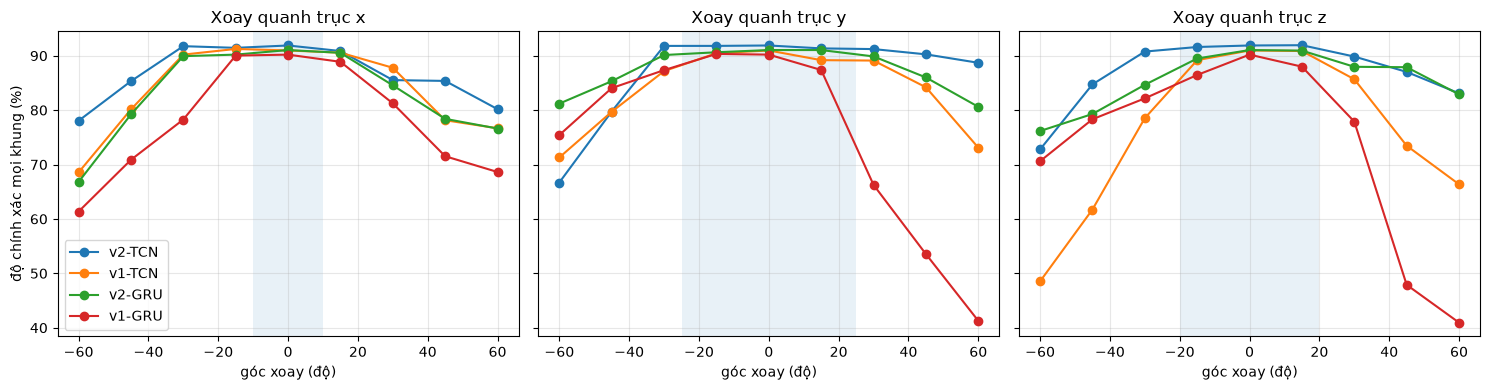

In [7]:
#cell 7: vẽ độ chính xác theo góc (vùng tô nhạt = khoảng góc đã train ở 04)
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, axis_name in zip(axs, AXES):
    for name in nets:
        g = res[(res["trục"] == axis_name) & (res["model"] == name)]
        a.plot(g["góc"], g["acc_all"], marker="o", label=name)
    a.axvspan(-TRAIN_RANGE[axis_name], TRAIN_RANGE[axis_name], alpha=0.1)
    a.set_title(f"Xoay quanh trục {axis_name}")
    a.set_xlabel("góc xoay (độ)")
    a.grid(alpha=0.3)
axs[0].set_ylabel("độ chính xác mọi khung (%)")
axs[0].legend()
plt.tight_layout()
plt.show()

In [8]:
#cell 8: xoay tổng hợp cả 3 trục cùng lúc (mỗi video một góc ngẫu nhiên trong ±mag, giống tình huống webcam thật hơn)
g_rand = torch.Generator(device=dev).manual_seed(0)
REPEAT = 5

rows = []
for mag in [15, 30, 45]:
    acc = {name: [] for name in nets}
    for _ in range(REPEAT):
        rnd = lambda: (torch.rand(len(X), 1, 1, device=dev, generator=g_rand) * 2 - 1) * mag
        Xr = rotate_clip(X, M, rnd(), rnd(), rnd())
        for name, net in nets.items():
            acc[name].append(evaluate(net, Xr))
    for name, lst in acc.items():
        rows.append({"±mag (độ)": mag, "model": name,
                     "acc_all (%)": np.nanmean([r["acc_all"] for r in lst]),
                     f"acc_conf ≥{THR} (%)": np.nanmean([r["acc_conf"] for r in lst]),
                     "coverage (%)": np.nanmean([r["coverage"] for r in lst])})
display(pd.DataFrame(rows).round(1))

,±mag (độ),model,acc_all (%),acc_conf ≥0.7 (%),coverage (%)
0,15,v2-TCN,91.9,98.8,81.5
1,15,v1-TCN,89.6,95.6,85.4
2,15,v2-GRU,90.2,94.3,88.9
3,15,v1-GRU,87.3,91.0,88.7
4,30,v2-TCN,90.7,98.1,80.1
5,30,v1-TCN,84.0,91.3,78.4
6,30,v2-GRU,85.6,91.1,86.4
7,30,v1-GRU,77.1,80.4,86.3
8,45,v2-TCN,84.4,91.1,76.9
9,45,v1-TCN,70.7,81.3,74.4


## Cách đọc kết quả
- Độ chính xác ở **0°** không phải 100%. Những khung đầu clip tay chưa ra cử chỉ nên khó đoán. Hãy so sánh các góc khác với chính con số ở 0°, không so với 100%.
- Nếu độ chính xác tụt sớm **trong vùng tô nhạt** (khoảng đã train), vấn đề không nằm ở độ rộng góc mà ở chỗ khác.
- Nếu độ chính xác tụt **ngoài vùng tô nhạt**, mở rộng góc augmentation ở Task 6b sẽ có tác dụng.
- `acc_conf` cao nhưng `coverage` thấp nghĩa là model biết mình không chắc. `acc_conf` thấp nghĩa là model tự tin mà vẫn sai, đây đúng là lỗi ở vấn đề 9.
- Hãy chép các bảng ở cell 5, 6 và 8 vào phần Ghi chép tiến trình.